# 01 · Menggabungkan data mentah stok beras

Notebook ini mengubah **data mentah** di `data_raw/` menjadi **satu panel gabungan** di `data_gabungan/`.
Panel itulah satu-satunya masukan notebook model berikutnya (`02_model_stok_beras.ipynb`).

```
beras_colab/
├── 01_gabung_data.ipynb          ← notebook ini
├── 02_model_stok_beras.ipynb     ← model Bayesian, hanya membaca data_gabungan/
├── data_raw/
│   ├── inatrade/Non_PAW_dari_nol.xlsm      laporan distribusi INATRADE (sheet "2024-2026")
│   ├── bps/*.json                           respons WebAPI BPS apa adanya (nama = var_tahun)
│   ├── publik/jangkar_publik.csv            survei stok, stok BULOG, impor, konsumsi & neraca Bapanas + link
│   └── usda/psd_beras_indonesia.csv         potongan USDA PSD (Indonesia, Rice Milled) — pembanding
└── data_gabungan/                ← dibuat notebook ini
    ├── panel_beras.csv           panel panjang: wilayah × bulan × variabel (+ satuan, sumber, status)
    ├── panel_beras_lebar.csv     panel yang sama, satu kolom per variabel (untuk dilihat)
    ├── jangkar.csv               angka level nasional: survei stok, stok BULOG, konsumsi & neraca Bapanas, USDA
    └── arus.csv                  kiriman antar provinsi dari rincian INATRADE
```

**Cara menjalankan di Colab:** unggah seluruh folder `beras_colab` ke Google Drive (mis. ke `MyDrive/`), buka
notebook ini di Colab, ubah `BASE` di sel pertama bila foldernya di tempat lain, lalu *Runtime → Run all*
(± 1 menit; tidak perlu kunci API karena respons BPS sudah tersimpan di `data_raw/bps/`).

**Varian INATRADE:** ubah `BARIS` di sel pertama menjadi `'nonpaw'` atau `'paw'` untuk membuat panel dengan
baris Non PAW saja atau PAW saja (disimpan sebagai `panel_beras_nonpaw.csv`, dst.).

In [1]:
import os, sys, json, re, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DI_COLAB = 'google.colab' in sys.modules
if DI_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/beras_colab'   # <- ganti bila folder diunggah ke tempat lain
else:
    BASE = os.path.abspath('.')                    # dijalankan dari dalam folder beras_colab
RAW = os.path.join(BASE, 'data_raw')
GAB = os.path.join(BASE, 'data_gabungan')
assert os.path.isdir(RAW), f'folder data_raw tidak ditemukan di {BASE}'
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

BARIS = 'semua'     # 'semua' (PAW + Non PAW, dasar), 'nonpaw', atau 'paw'
AWAL, AKHIR = '2022-07', '2026-12'   # bulan panel; model memakai Jul 2022 - Sep 2026, prakiraan Okt-Des 2026
SUFFIX = '' if BARIS == 'semua' else '_' + BARIS
os.makedirs(GAB, exist_ok=True)
PER = [str(p) for p in pd.period_range(AWAL, AKHIR, freq='M')]
print('folder:', BASE, '| bulan panel:', PER[0], '-', PER[-1], f'({len(PER)})', '| baris INATRADE:', BARIS)

folder: /tmp/claude-0/-home-user-tess/ddd430f4-a61f-57d4-a8ae-772effc3783d/scratchpad/colab/beras_colab | bulan panel: 2022-07 - 2026-12 (54) | baris INATRADE: semua


In [2]:
# Wilayah: 38 provinsi, 6 kelompok pulau
PULAU = {'Sumatera': ['ACEH', 'SUMATERA UTARA', 'SUMATERA BARAT', 'RIAU', 'JAMBI', 'SUMATERA SELATAN', 'BENGKULU', 'LAMPUNG', 'KEPULAUAN BANGKA BELITUNG', 'KEPULAUAN RIAU'], 'Jawa': ['DKI JAKARTA', 'JAWA BARAT', 'JAWA TENGAH', 'DAERAH ISTIMEWA YOGYAKARTA', 'JAWA TIMUR', 'BANTEN'], 'Bali & Nusa Tenggara': ['BALI', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR'], 'Kalimantan': ['KALIMANTAN BARAT', 'KALIMANTAN TENGAH', 'KALIMANTAN SELATAN', 'KALIMANTAN TIMUR', 'KALIMANTAN UTARA'], 'Sulawesi': ['SULAWESI UTARA', 'SULAWESI TENGAH', 'SULAWESI SELATAN', 'SULAWESI TENGGARA', 'GORONTALO', 'SULAWESI BARAT'], 'Maluku & Papua': ['MALUKU', 'MALUKU UTARA', 'PAPUA BARAT', 'PAPUA BARAT DAYA', 'PAPUA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']}
PROV = [p for v in PULAU.values() for p in v]
PULAU_DARI = {p: k for k, v in PULAU.items() for p in v}
KONV = 0.5762  # GKG -> beras (BPS 2024: 53,14 juta ton GKG = 30,62 juta ton beras)

## 1. INATRADE: dari baris laporan ke panel provinsi

Data mentah: satu baris = satu rincian penyaluran/pengadaan. Nilai kepala laporan (pengadaan, penyaluran,
stok awal, stok akhir) **berulang** di setiap baris rincian, jadi satu laporan = perusahaan × bulan × subkomoditas
dan nilai kepalanya diambil sekali.

Langkah:
1. Ambil baris `Jenis Komoditi = BERAS`; tandai **Non PAW** (provinsi perusahaan = provinsi penyaluran) dan **PAW**
   (berbeda). `BARIS` memilih baris mana yang dipakai.
2. Satukan per perusahaan × bulan × subkomoditas.
3. **Koreksi satuan:** laporan yang volumenya ≥ 100× median laporan perusahaan itu sendiri dianggap ditulis
   dalam kg → dibagi 1.000.
4. **BULOG** (kode perusahaan 00372) dipisah dari pedagang.

In [3]:
def kosong(v):
    return v is None or (isinstance(v, float) and math.isnan(v)) or str(v).strip() == ''

def U(v):
    return '' if kosong(v) else re.sub(' +', ' ', str(v).strip().upper())

def angka(v):
    """Angka dari sel; format Indonesia 1.234,5 dikenali. None bila kosong."""
    if kosong(v):
        return None
    if isinstance(v, (int, float)):
        return float(v)
    t = ''.join(c for c in str(v) if c.isdigit() or c in ',.-')
    if not any(c.isdigit() for c in t):
        return None
    if re.fullmatch(r'-?\d{1,3}(\.\d{3})+(,\d*)?', t):
        t = t.replace('.', '').replace(',', '.')
    else:
        t = t.replace(',', '')
    try:
        return float(re.match(r'-?\d*\.?\d*', t).group(0))
    except ValueError:
        return 0.0

def a0(v):
    x = angka(v)
    return 0.0 if x is None else x

def normprov(v):
    s = U(v)
    for p in ('PROVINSI ', 'PROV. '):
        if s.startswith(p):
            s = s[len(p):].strip()
    return s

BULAN = {'JANUARI': 1, 'FEBRUARI': 2, 'MARET': 3, 'APRIL': 4, 'MEI': 5, 'JUNI': 6, 'JULI': 7,
         'AGUSTUS': 8, 'SEPTEMBER': 9, 'OKTOBER': 10, 'NOVEMBER': 11, 'DESEMBER': 12}

def periode(bulan, tahun):
    b, t = BULAN.get(U(bulan)), angka(tahun)
    return f'{int(t)}-{b:02d}' if b and t is not None else None

KODE_BULOG, AMBANG_KG = '00372', 100
Q = ['Pengadaan', 'Penyaluran', 'Stok Awal', 'Stok Akhir']

In [4]:
S = pd.read_excel(os.path.join(RAW, 'inatrade', 'Non_PAW_dari_nol.xlsm'), sheet_name='2024-2026', dtype=object)
B = S[S['Jenis Komoditi'].map(U) == 'BERAS'].copy().reset_index(drop=True)
B['kode'] = B['Nama Perusahaan'].astype(str).str.strip().str.zfill(5)
B['periode'] = [periode(b, t) for b, t in zip(B['Bulan'], B['Tahun'])]
B['sub'] = B['Sub Komoditi'].astype(str).str.strip()
B['prov'] = B['Provinsi Perusahaan'].map(normprov)
B['prov_tujuan'] = B['Provinsi Penyaluran'].map(normprov)
B['prov_asal'] = B['Asal Pengadaan'].map(normprov)
for c in Q + ['Rincian Pengadaan', 'Rincian Penyaluran', 'Harga Jual']:
    B[c] = B[c].map(a0)
B = B.dropna(subset=['periode'])
B['jenis_baris'] = np.where(B.prov_tujuan == '', 'tanpa tujuan', np.where(B.prov_tujuan == B.prov, 'Non PAW', 'PAW'))
print(f'{len(S):,} baris semua komoditas; {len(B):,} baris beras'); print(B.jenis_baris.value_counts().to_string())
if BARIS == 'nonpaw':
    B = B[B.jenis_baris == 'Non PAW']
elif BARIS == 'paw':
    B = B[B.jenis_baris == 'PAW']
B = B.reset_index(drop=True)
print('dipakai:', len(B), 'baris')

27,665 baris semua komoditas; 3,662 baris beras
jenis_baris
Non PAW         1947
PAW             1684
tanpa tujuan      31
dipakai: 3662 baris


In [5]:
L = B.groupby(['kode', 'periode', 'sub'], as_index=False).agg(
    prov=('prov', 'first'), peng=('Pengadaan', 'max'), peny=('Penyaluran', 'max'),
    sa=('Stok Awal', 'max'), sk=('Stok Akhir', 'max'), baris=('periode', 'size'))
basis = {}
for k, g in L.groupby(['kode', 'sub']):
    v = g[['peny', 'sa', 'sk', 'peng']].replace(0, np.nan).stack()
    basis[k] = v.median() if len(v) else np.nan
L['basis'] = [basis[(a, b)] for a, b in zip(L['kode'], L['sub'])]
besar = L[['peny', 'sa', 'sk', 'peng']].max(axis=1) / L['basis']
L['faktor'] = np.where((L['basis'] > 0) & (besar >= AMBANG_KG), 1 / 1000, 1.0)
for c in ['peng', 'peny', 'sa', 'sk']:
    L[c] = L[c] * L['faktor']
L['bulog'] = L['kode'] == KODE_BULOG
print(f'{len(L):,} laporan; {int((L.faktor < 1).sum())} dikoreksi kg -> ton; BULOG {int(L.bulog.sum())} laporan')
L.head()

1,683 laporan; 58 dikoreksi kg -> ton; BULOG 10 laporan


,kode,periode,sub,prov,peng,peny,sa,sk,baris,basis,faktor,bulog
0,00003,2024-11,Beras Medium,KEPULAUAN BANGKA BELITUNG,25.365000,25.038000,10.640,14.09800,12,39.5750,1.000,False
1,00003,2024-12,Beras Medium,KEPULAUAN BANGKA BELITUNG,1.400000,0.048190,13.780,13.78652,6,39.5750,0.001,False
2,00003,2025-01,Beras BULOG,KEPULAUAN BANGKA BELITUNG,24.000000,26.565000,8.165,5.60000,1,6.8825,1.000,False
3,00003,2025-01,Beras Medium,KEPULAUAN BANGKA BELITUNG,0.075035,0.078728,33.440,33.46267,2,39.5750,0.001,False
4,00003,2025-02,Beras BULOG,KEPULAUAN BANGKA BELITUNG,0.000000,3.000000,3.000,0.00000,1,6.8825,1.000,False


In [6]:
# panel provinsi pedagang (tanpa BULOG) dan seri BULOG nasional dari INATRADE
T_ = L[~L.bulog]
P_inat = T_.groupby(['prov', 'periode']).agg(inatrade_pelapor=('kode', 'nunique'),
                                             inatrade_stok_ton=('sk', 'sum'),
                                             inatrade_penyaluran_ton=('peny', 'sum')).reset_index()
P_inat = P_inat[P_inat.prov.isin(PROV)]
bulog_inat = L[L.bulog].groupby('periode')['sk'].sum()

# arus antar provinsi dari rincian (faktor koreksi satuan laporan ikut diterapkan)
fx = dict(zip(zip(L['kode'], L['periode'], L['sub']), L['faktor']))
Bn = B[B['kode'] != KODE_BULOG].copy()
f = [fx.get(k, 1.0) for k in zip(Bn['kode'], Bn['periode'], Bn['sub'])]
Bn['vol_jual'], Bn['vol_beli'] = Bn['Rincian Penyaluran'] * f, Bn['Rincian Pengadaan'] * f
jual = Bn[(Bn.prov_tujuan != '') & (Bn.vol_jual > 0)].groupby(['periode', 'prov', 'prov_tujuan'], as_index=False)['vol_jual'].sum()
jual.columns = ['periode', 'asal', 'tujuan', 'ton']
beli = Bn[(Bn.prov_asal != '') & (Bn.vol_beli > 0)].groupby(['periode', 'prov_asal', 'prov'], as_index=False)['vol_beli'].sum()
beli.columns = ['periode', 'asal', 'tujuan', 'ton']
ARUS = pd.concat([jual.assign(jenis='penyaluran'), beli.assign(jenis='pengadaan')], ignore_index=True)
print(P_inat.prov.nunique(), 'provinsi pelapor;', len(P_inat), 'sel provinsi-bulan;', len(ARUS), 'baris arus')

20 provinsi pelapor; 404 sel provinsi-bulan; 2222 baris arus


## 2. BPS: respons WebAPI → tabel rapi

File di `data_raw/bps/` adalah respons WebAPI BPS apa adanya (`<var>_<th>.json`, th = tahun − 1900).
Bila sebuah file belum ada dan env var `BPS_API_KEY` diisi, notebook mengunduhnya.

| var | isi | dipakai untuk |
|---|---|---|
| 2506 | produksi padi bulanan per provinsi (KSA), 2025–2026, Sep–Des 2026 angka potensi | produksi bulanan |
| 1498 | luas panen & produksi padi tahunan per provinsi, 2022–2024 | produksi 2022–2024 (dipecah dengan pola bulanan 2025) |
| 2094 | konsumsi per kapita seminggu padi-padian per kab/kota (Susenas), 2022–2025 | konsumsi rumah tangga |
| 2790 | penduduk per kab/kota, 2022–2025 | bobot dan pengali konsumsi |
| 500, 2277 | harga beras di penggilingan per kualitas, 2022–2025 | sinyal harga |

In [7]:
BPS_URL = 'https://webapi.bps.go.id/v1/api/list/model/data/lang/ind/domain/0000/var/{var}/th/{th}/key/{key}/'

def ambil(var, tahun):
    th = ';'.join(str(y - 1900) for y in tahun)
    f = os.path.join(RAW, 'bps', f'{var}_{th.replace(";", "-")}.json')
    if not os.path.exists(f):
        import urllib.request
        url = BPS_URL.format(var=var, th=th, key=os.environ['BPS_API_KEY'])
        with urllib.request.urlopen(url, timeout=120) as r, open(f, 'wb') as h:
            h.write(r.read())
    with open(f) as h:
        return json.load(h)

def urai(d):
    """datacontent BPS -> DataFrame. Kunci datacontent = vervar + var + turvar + th_id + turtahun."""
    var = str(d['var'][0]['val'])
    vv = {str(x['val']): x['label'] for x in d['vervar']}
    tv = [str(x['val']) for x in d['turvar']]
    th = {str(x['val']): x['label'] for x in d['tahun']}
    tt = [str(x['val']) for x in d['turtahun']]
    rows = []
    for k, v in d['datacontent'].items():
        for a in vv:
            if not k.startswith(a + var):
                continue
            rest = k[len(a) + len(var):]
            for b in tv:
                if not rest.startswith(b):
                    continue
                r2 = rest[len(b):]
                for c in th:
                    if r2.startswith(c) and r2[len(c):] in tt:
                        rows.append((a, vv[a], b, int(th[c]), int(r2[len(c):]), v))
    return pd.DataFrame(rows, columns=['kode', 'wilayah', 'turvar', 'tahun', 'turtahun', 'nilai'])

def nama_prov(s):
    s = s.replace('<b>', '').replace('</b>', '').strip().upper()
    return {'KEP. BANGKA BELITUNG': 'KEPULAUAN BANGKA BELITUNG', 'KEP. RIAU': 'KEPULAUAN RIAU',
            'DI YOGYAKARTA': 'DAERAH ISTIMEWA YOGYAKARTA', 'D I YOGYAKARTA': 'DAERAH ISTIMEWA YOGYAKARTA'}.get(s, s)

In [8]:
# produksi padi bulanan KSA (2025-2026)
m = urai(ambil(2506, [2025, 2026]))
m = m[(m.turtahun <= 12) & (m.kode != '9999')].copy()
m['prov'] = m.wilayah.map(nama_prov)
m['periode'] = m.tahun.astype(str) + '-' + m.turtahun.map('{:02d}'.format)
KSA = m[m.prov.isin(PROV)][['prov', 'periode', 'nilai']].rename(columns={'nilai': 'padi_gkg_ton'})

# produksi padi tahunan (turvar 1193 = produksi, ton GKG)
a = urai(ambil(1498, [2022, 2023, 2024]))
a = a[a.turvar == '1193'].copy()
a['prov'] = a.wilayah.map(nama_prov)
THN = a[a.prov != 'INDONESIA'][['prov', 'tahun', 'nilai']].rename(columns={'nilai': 'padi_gkg_ton'})
tmap = {(r.prov, r.tahun): r.padi_gkg_ton for r in THN.itertuples() if not np.isnan(r.padi_gkg_ton)}
# 2022: provinsi pemekaran Papua masih tergabung di provinsi induk -> dibagi menurut pangsa 2023
for induk, anak in [('PAPUA', ['PAPUA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']),
                    ('PAPUA BARAT', ['PAPUA BARAT', 'PAPUA BARAT DAYA'])]:
    tot22, tot23 = tmap[(induk, 2022)], sum(tmap[(x, 2023)] for x in anak)
    for x in anak:
        tmap[(x, 2022)] = tot22 * tmap[(x, 2023)] / tot23

# pola musim 2025 per provinsi untuk memecah angka tahunan 2022-2024 ke bulanan
k25 = KSA[KSA.periode.str.startswith('2025')].copy()
k25['m'] = k25.periode.str[5:].astype(int)
pola = k25.pivot(index='prov', columns='m', values='padi_gkg_ton')
pola = pola.div(pola.sum(axis=1), axis=0)
kmap = {(r.prov, r.periode): r.padi_gkg_ton for r in KSA.itertuples()}
rows = []
for p in PROV:
    for b in PER:
        y, mm = int(b[:4]), int(b[5:])
        if (p, b) in kmap:
            v, st = kmap[(p, b)], 'KSA bulanan' + (' (potensi)' if b >= '2026-09' else '')
        elif (p, y) in tmap:
            v, st = tmap[(p, y)] * pola.loc[p, mm], 'KSA tahunan x pola 2025'
        else:
            v, st = np.nan, 'belum ada'
        rows.append((p, b, v, st))
PROD = pd.DataFrame(rows, columns=['prov', 'periode', 'padi_gkg_ton', 'status'])
print(PROD.status.value_counts().to_string())

status
KSA tahunan x pola 2025    1140
KSA bulanan                 760
KSA bulanan (potensi)       114
belum ada                    38


In [9]:
# konsumsi beras rumah tangga: Susenas per kab/kota x penduduk kab/kota -> provinsi
rows = []
for y in [2022, 2023, 2024, 2025]:
    k = urai(ambil(2094, [y]))
    k = k[k.turvar == '1735'][['kode', 'nilai']].rename(columns={'nilai': 'kg_minggu'})   # 1735 = beras
    p = urai(ambil(2790, [y]))
    p = p[p.turvar == '23'][['kode', 'wilayah', 'nilai']].rename(columns={'nilai': 'jiwa'})  # 23 = total umur
    prov = p[p.kode.str.endswith('00')].copy()
    prov['prov'] = prov.wilayah.map(nama_prov)
    kab = p[~p.kode.str.endswith('00')].merge(k, on='kode', how='left')
    kab['pkode'] = kab.kode.str[:2] + '00'
    for pk, g in kab.groupby('pkode'):
        g2 = g.dropna(subset=['kg_minggu'])
        nm = prov.loc[prov.kode == pk, 'prov']
        if not len(nm) or not len(g2):
            continue
        jiwa = float(prov.loc[prov.kode == pk, 'jiwa'].iloc[0])
        rows.append((nm.iloc[0], y, jiwa, (g2.kg_minggu * g2.jiwa).sum() / g2.jiwa.sum()))
KONS = pd.DataFrame(rows, columns=['prov', 'tahun', 'penduduk', 'beras_kg_kapita_minggu'])
KONS['konsumsi_rt_ton_bulan'] = KONS.penduduk * KONS.beras_kg_kapita_minggu * 52 / 12 / 1000
print(KONS.groupby('tahun').konsumsi_rt_ton_bulan.sum().mul(12 / 1e6).round(2).rename('juta ton/tahun').to_string())

# harga beras di penggilingan (nasional, per kualitas)
hs = []
for var, th in [(500, [2022, 2023]), (2277, [2024, 2025])]:
    x = urai(ambil(var, th))
    x['kualitas'] = x.wilayah.str.strip().str.upper()
    hs.append(x)
H = pd.concat(hs)
H = H[(H.turtahun <= 12) & H.kualitas.isin(['PREMIUM', 'MEDIUM'])].copy()
H['periode'] = H.tahun.astype(str) + '-' + H.turtahun.map('{:02d}'.format)
H = H[['periode', 'kualitas', 'nilai']].rename(columns={'nilai': 'rp_kg'})

tahun
2022    22.58
2023    22.83
2024    22.53
2025    22.60


## 3. Angka publik dan pembanding

`jangkar_publik.csv` berisi angka level nasional yang dikumpulkan dari rilis dan berita resmi, masing-masing
dengan link sumbernya: survei stok (SCBN BPS Jun 2022; SSBAT Bapanas-BPS Des 2022 dan Des 2023), stok BULOG,
impor tahunan, konsumsi dan neraca Bapanas. Impor tahunan dibagi rata per bulan (2022: 0,3 juta ton dibagi ke
Jul–Des). USDA PSD hanya pembanding.

In [10]:
J = pd.read_csv(os.path.join(RAW, 'publik', 'jangkar_publik.csv'))
imp = {b: 0.0 for b in PER}
for r in J[J.jenis == 'impor'].itertuples():
    if r.periode == '2022-H2':
        for b in PER:
            if '2022-07' <= b <= '2022-12':
                imp[b] = r.nilai_juta_ton * 1e6 / 6
    else:
        for b in PER:
            if b.startswith(r.periode):
                imp[b] = r.nilai_juta_ton * 1e6 / 12
USDA = pd.read_csv(os.path.join(RAW, 'usda', 'psd_beras_indonesia.csv'))
usda_stok = USDA[(USDA.Attribute_Description == 'Ending Stocks') & (USDA.Market_Year >= 2021)]
J.drop(columns=['url']).head(25)

,jenis,periode,nilai_juta_ton,sumber,catatan
0,survei_bps_scbn,2022-06,9.710,BPS Survei Cadangan Beras Nasional 2022,"RT 6,6; BULOG 1,11; pedagang 1,04; penggilinga..."
1,survei_bapanas,2022-12,4.060,Survei Stok Beras Akhir Tahun (SSBAT) Bapanas-BPS,posisi 31 Des 2022
2,survei_bapanas,2023-12,4.130,Survei Stok Beras Akhir Tahun (SSBAT) Bapanas-BPS,"posisi 31 Des 2023; RT 66,34%, BULOG 19,6%, pe..."
3,bulog_publik,2023-03,0.245,BULOG,per 31 Maret 2023
4,bulog_publik,2023-12,1.260,BULOG,per 20 Desember 2023
5,bulog_publik,2024-12,2.000,BULOG / Menko Pangan,"2,07 per 10 Des; perkiraan akhir tahun 1,95"
6,bulog_publik,2025-01,1.940,BULOG,per 4 Februari 2025
7,bulog_publik,2025-05,4.000,BULOG,awal Juni 2025
8,bulog_publik,2025-11,3.800,BULOG,per 20 November 2025
9,bulog_publik,2025-12,3.530,Bapanas,"perkiraan akhir 2025 (3,5 per 22 Des)"


## 4. Gabungkan menjadi satu panel

Panel panjang dengan kolom `wilayah, tingkat, pulau, periode, variabel, nilai, satuan, sumber, status`.
Variabel per provinsi: produksi padi dan beras, konsumsi rumah tangga, penduduk, stok/penyaluran/pelapor
INATRADE. Variabel nasional (`wilayah = INDONESIA`): impor, harga penggilingan, stok BULOG laporan INATRADE.

- **Konsumsi 2026** = konsumsi 2025 × 1,01 (Susenas 2026 belum terbit; status `turunan`).
- Sel tanpa data tidak ditulis (bukan nol), kecuali impor yang memang nol pada 2025–2026.

In [11]:
rows = []
def tambah(w, tk, b, var, v, sat, src, st):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return
    rows.append((w, tk, PULAU_DARI.get(w, ''), b, var, float(v), sat, src, st))

kc = {(r.prov, r.tahun): r for r in KONS.itertuples()}
for r in PROD.itertuples():
    tambah(r.prov, 'provinsi', r.periode, 'produksi_padi_gkg_ton', r.padi_gkg_ton, 'ton GKG', 'BPS var 2506/1498', r.status)
    tambah(r.prov, 'provinsi', r.periode, 'produksi_beras_ton', r.padi_gkg_ton * KONV, 'ton beras',
           'BPS var 2506/1498 x 0,5762', r.status)
for p in PROV:
    for b in PER:
        y = int(b[:4])
        k = kc[(p, min(y, 2025))]
        f = 1.01 if y >= 2026 else 1.0
        st = 'Susenas tahun yang sama' if y <= 2025 else 'turunan: 2025 x 1,01'
        tambah(p, 'provinsi', b, 'konsumsi_rt_ton', k.konsumsi_rt_ton_bulan * f, 'ton beras per bulan', 'BPS var 2094 x 2790', st)
        tambah(p, 'provinsi', b, 'penduduk', k.penduduk, 'jiwa', 'BPS var 2790', st)
for r in P_inat.itertuples():
    if r.periode in PER:
        for v in ['inatrade_stok_ton', 'inatrade_penyaluran_ton', 'inatrade_pelapor']:
            tambah(r.prov, 'provinsi', r.periode, v, getattr(r, v), 'perusahaan' if v.endswith('pelapor') else 'ton',
                   f'INATRADE ({BARIS})', 'laporan, kg->ton dikoreksi')
for b in PER:
    tambah('INDONESIA', 'nasional', b, 'impor_ton', imp[b], 'ton beras', 'jangkar_publik.csv (BPS)', 'tahunan dibagi rata')
for r in H.itertuples():
    if r.periode in PER:
        tambah('INDONESIA', 'nasional', r.periode, 'harga_penggilingan_' + r.kualitas.lower(), r.rp_kg, 'Rp/kg', 'BPS var 500/2277', 'resmi')
for b, v in bulog_inat.items():
    if b in PER:
        tambah('INDONESIA', 'nasional', b, 'bulog_inatrade_stok_ton', v, 'ton', 'INATRADE kode 00372', 'laporan')

PANEL = pd.DataFrame(rows, columns=['wilayah', 'tingkat', 'pulau', 'periode', 'variabel', 'nilai', 'satuan', 'sumber', 'status'])
PANEL.to_csv(os.path.join(GAB, f'panel_beras{SUFFIX}.csv'), index=False)
LEBAR = PANEL.pivot_table(index=['wilayah', 'tingkat', 'pulau', 'periode'], columns='variabel', values='nilai').reset_index()
LEBAR.to_csv(os.path.join(GAB, f'panel_beras_lebar{SUFFIX}.csv'), index=False)

# jangkar level nasional (tanpa impor; impor sudah masuk panel) + USDA sebagai pembanding
JG = J[J.jenis != 'impor'].copy()
JG['peran'] = np.where(JG.jenis.isin(['survei_bps_scbn', 'survei_bapanas', 'bulog_publik', 'konsumsi_bapanas']), 'dipakai model', 'pembanding')
us = pd.DataFrame({'jenis': 'usda_stok_akhir', 'periode': usda_stok.Market_Year.astype(int).astype(str) + '-12',
                   'nilai_juta_ton': usda_stok.Value / 1000, 'sumber': 'USDA PSD', 'catatan': 'stok akhir tahun pasar (pembanding)',
                   'url': 'https://apps.fas.usda.gov/psdonline/downloads/psd_grains_pulses_csv.zip', 'peran': 'pembanding'})
JG = pd.concat([JG, us], ignore_index=True)
JG.to_csv(os.path.join(GAB, 'jangkar.csv'), index=False)
ARUS.to_csv(os.path.join(GAB, f'arus{SUFFIX}.csv'), index=False)
print(f'panel_beras{SUFFIX}.csv: {len(PANEL):,} baris, {PANEL.variabel.nunique()} variabel, {PANEL.wilayah.nunique()} wilayah')
PANEL.groupby(['variabel', 'status']).agg(baris=('nilai', 'size'), wilayah=('wilayah', 'nunique'),
                                          dari=('periode', 'min'), sampai=('periode', 'max')).reset_index()

panel_beras.csv: 9,490 baris, 11 variabel, 39 wilayah


,variabel,status,baris,wilayah,dari,sampai
0,bulog_inatrade_stok_ton,laporan,8,1,2025-09,2026-09
1,harga_penggilingan_medium,resmi,42,1,2022-07,2025-12
2,harga_penggilingan_premium,resmi,42,1,2022-07,2025-12
3,impor_ton,tahunan dibagi rata,54,1,2022-07,2026-12
4,inatrade_pelapor,"laporan, kg->ton dikoreksi",404,20,2024-01,2026-09
5,inatrade_penyaluran_ton,"laporan, kg->ton dikoreksi",404,20,2024-01,2026-09
6,inatrade_stok_ton,"laporan, kg->ton dikoreksi",404,20,2024-01,2026-09
7,konsumsi_rt_ton,Susenas tahun yang sama,1596,38,2022-07,2025-12
8,konsumsi_rt_ton,"turunan: 2025 x 1,01",456,38,2026-01,2026-12
9,penduduk,Susenas tahun yang sama,1596,38,2022-07,2025-12


## 5. Cek cepat panel gabungan

juta ton per tahun (2022: Jul-Des; 2026: produksi Jan-Nov, Sep-Nov angka potensi)
         produksi beras  konsumsi rumah tangga  impor
periode                                              
2022              14.00                  11.29   0.30
2023              31.10                  22.83   3.06
2024              30.62                  22.53   4.52
2025              34.69                  22.60   0.00
2026              32.34                  22.83   0.00


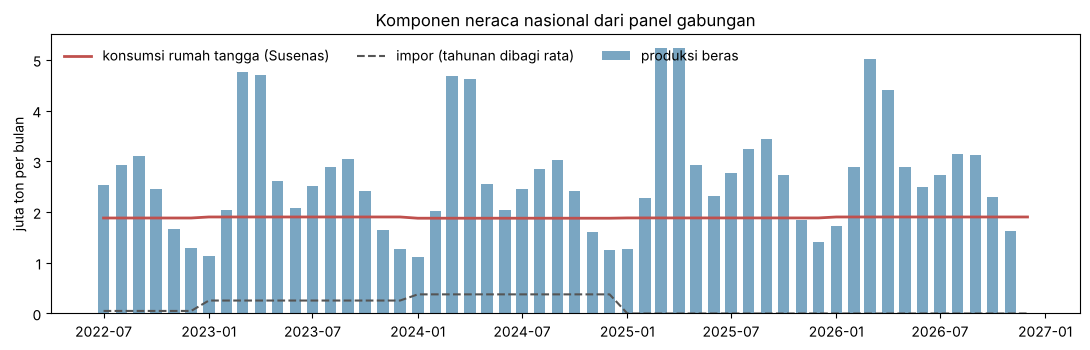

periode,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,...,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
provinsi_pelapor,6.0,6.0,6.0,7.0,6.0,6.0,6.0,5.0,8.0,11.0,12.0,14.0,14.0,13.0,13.0,...,15.0,14.0,14.0,14.0,13.0,13.0,13.0,15.0,17.0,16.0,16.0,19.0,17.0,17.0,17.0
perusahaan,11.0,13.0,13.0,13.0,11.0,11.0,12.0,9.0,15.0,31.0,52.0,52.0,48.0,47.0,48.0,...,58.0,50.0,53.0,57.0,54.0,57.0,51.0,51.0,57.0,55.0,59.0,65.0,61.0,59.0,55.0
stok_inatrade_ribu_ton,3.8,2.7,2.3,3.5,4.4,5.3,6.7,7.3,8.7,57.5,74.1,35.0,34.0,26.6,34.2,...,32.3,30.2,35.0,33.0,27.0,28.9,18.6,30.4,36.6,39.3,21.2,39.8,49.0,27.4,29.9


In [12]:
nas = LEBAR[LEBAR.tingkat == 'provinsi'].groupby('periode')[['produksi_beras_ton', 'konsumsi_rt_ton']].sum() / 1e6
nas['impor'] = LEBAR[LEBAR.wilayah == 'INDONESIA'].set_index('periode').impor_ton / 1e6
th = nas.groupby(nas.index.str[:4]).sum().round(2)
th.columns = ['produksi beras', 'konsumsi rumah tangga', 'impor']
print('juta ton per tahun (2022: Jul-Des; 2026: produksi Jan-Nov, Sep-Nov angka potensi)'); print(th.to_string())

fig, ax = plt.subplots(figsize=(11, 3.6))
x = pd.PeriodIndex(nas.index, freq='M').to_timestamp()
ax.bar(x, nas.produksi_beras_ton, width=20, color='#7aa6c2', label='produksi beras')
ax.plot(x, nas.konsumsi_rt_ton, color='#c0504d', lw=2, label='konsumsi rumah tangga (Susenas)')
ax.plot(x, nas.impor, color='#555', lw=1.5, ls='--', label='impor (tahunan dibagi rata)')
ax.set_ylabel('juta ton per bulan'); ax.legend(frameon=False, ncol=3); ax.set_title('Komponen neraca nasional dari panel gabungan')
plt.tight_layout(); plt.show()

cak = LEBAR[LEBAR.tingkat == 'provinsi'].groupby('periode').agg(provinsi_pelapor=('inatrade_pelapor', 'count'),
                                                                  perusahaan=('inatrade_pelapor', 'sum'),
                                                                  stok_inatrade_ribu_ton=('inatrade_stok_ton', 'sum'))
cak['stok_inatrade_ribu_ton'] /= 1e3
cak[cak.provinsi_pelapor > 0].round(1).T